# Lecture 24 — Data, Control and Structural Hazards

> Dr. Janibul Bashir · Full transcript retrieved · Approximately 62 minutes
>
> I've retrieved the actual professor's transcript. Here's the lecture sequence:

| Timestamp | Topic |
|-----------|-------|
| 0:00–12:16 | Why ideal pipelines fail; definition of hazards |
| 12:16–35:15 | Data hazards: RAW, WAW and WAR |
| 35:15–47:00 | RAW dependencies and pipeline penalties |
| 47:00–59:31 | Control hazards and branch penalties |
| 59:31–1:02:12 | Structural hazards |

> 📌 We'll work through the examples and pipeline diagrams rather than memorizing the definitions.

---

## Part 1 — What is a Pipeline Hazard?

Recall the assumption of an **ideal pipeline**: instructions can advance every cycle without interfering with one another.

But consider:

```
I1: add x2, x3, x4
I2: sub x5, x6, x2
```

What happens here?

- `I1` produces a new value for `x2`.
- `I2` needs that value to calculate `x6 - x2`.

If `I2` reads `x2` before `I1` produces the new value, it may use outdated data.

> **Definition:** A **pipeline hazard** is a condition that prevents an instruction from proceeding through the pipeline in its scheduled cycle without risking incorrect execution or a resource conflict.

The professor identifies three types:

| Hazard | Cause |
|--------|-------|
| **Data Hazard** | Instruction depends on data produced or accessed by another instruction |
| **Control Hazard** | Next instruction depends on a branch or other change in control flow |
| **Structural Hazard** | Two operations need the same hardware resource simultaneously |

---

## Part 2 — Data Hazard: The Professor's Example

*Transcript: approximately 13:09–21:18*

Suppose:

$$x2 = 2, \quad x3 = 3, \quad x4 = 5, \quad x6 = 7$$

And execute:

```
I1: add x2, x3, x4
I2: sub x5, x6, x2
```

### What should happen?

**Instruction I1:**

$$x2 = 3 + 5 = \boxed{8}$$

**Instruction I2:**

$$x5 = 7 - 8 = \boxed{-1}$$

So the correct final results are:

$$\boxed{x2 = 8, \quad x5 = -1}$$

### What if we ignore the dependency?

Look at the pipeline schedule:

| Stage | Cycle 1 | Cycle 2 | Cycle 3 | Cycle 4 | Cycle 5 | Cycle 6 |
|-------|---------|---------|---------|---------|---------|---------|
| IF | I1 | I2 | — | — | — | — |
| ID | — | I1 | I2 | — | — | — |
| EX | — | — | I1 | I2 | — | — |
| MEM | — | — | — | I1 | I2 | — |
| WB | — | — | — | — | I1 | I2 |

During cycle 3:

- `I1` calculates `x2 = 8` in EX.
- `I2` reads register `x2` in ID.
- But `x2` still contains its old value, `2`, in the register file.

If the processor uses that stale operand without correction:

$$x5 = 7 - 2 = \boxed{5}$$

That's **incorrect**.

The correct result was $-1$.

### Why is this called RAW?

**RAW** stands for **Read After Write**.

`I1` must write the new value of `x2` before `I2` can safely consume that value, unless the processor uses forwarding to deliver it directly.

```
I1: add x2, x3, x4
        ↑
       WRITE x2

I2: sub x5, x6, x2
                ↑
               READ x2
```

This is also called a **true dependency** or **flow dependency**.

> 📌 The professor initially handles the problem by stalling `I2` until `I1` completes WB. That is the simplified **no-forwarding model** used for his penalty calculations. More advanced processors can use forwarding to reduce the wait.


# Lecture 24 — Part 3: WAW and WAR Data Hazards

**Professor's Transcript:** Approximately 22:00–35:15

The professor discusses three types of data dependencies:

| Dependency | Full Form | Alternative Name |
|---|---|---|
| RAW | Read After Write | True / Flow dependency |
| WAW | Write After Write | Output dependency |
| WAR | Write After Read | Anti-dependency |

> 📌 **Important distinction:** RAW represents real data flow, whereas WAW and WAR are name dependencies resulting from instructions sharing register names.

Let's understand why.

---

## 1. WAW — Write After Write

**Professor's Example:** Approximately 22:28–26:23

Consider two instructions:

```asm
I1: add x3, x5, x6
I2: add x3, x2, x1
```

Given:

$$
x5=5,\quad x6=6,\quad x2=2,\quad x1=1
$$

### 1.1 What Should Happen?

**Instruction I1:**

$$
x3=5+6=11
$$

**Instruction I2:**

$$
x3=2+1=3
$$

So the correct final value is:

$$
\boxed{x3=3}
$$

**Why?**

Because I2 comes after I1 in program order, and both write into the same destination register.

### 1.2 What If the Instructions Finish in the Wrong Order?

Imagine an out-of-order processor executes I2 first and then allows I1 to overwrite its result.

| Correct Order | Incorrect Order |
|---|---|
| I1 → I2 | I2 → I1 |
| **x3 = 3** | **x3 = 11** |
| I2 writes last | I1 overwrites I2 |

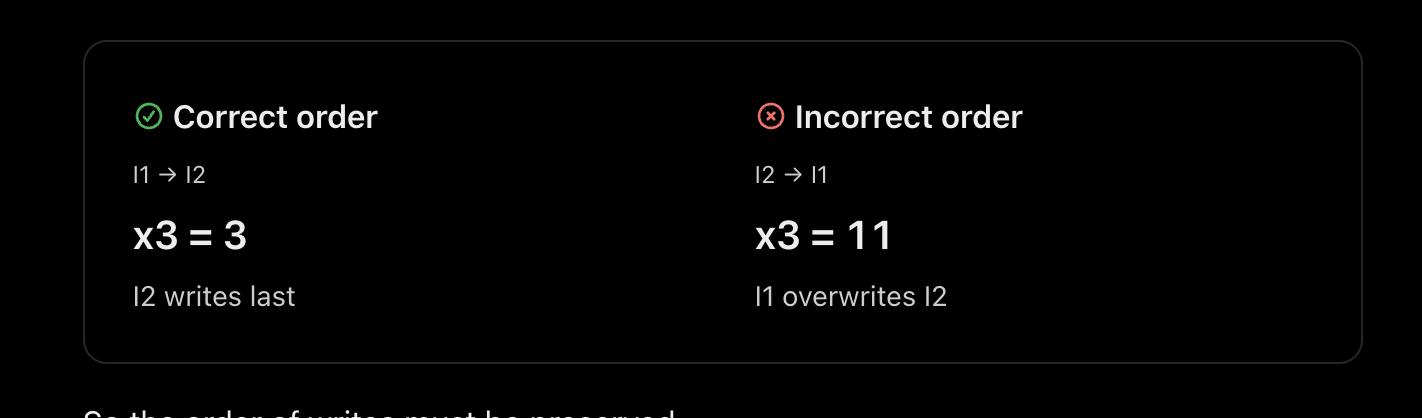

So the order of writes must be preserved.

This is called:

$$
\boxed{\text{WAW}=\text{Write After Write}}
$$

### Exam Definition

> **WAW Dependency:** A WAW dependency occurs when two instructions write to the same destination register, and reversing the order of those writes could produce an incorrect result.

Notice that neither instruction actually requires a value produced by the other.

They simply share a destination register.

That's why WAW is a **name dependency**, not a true data-flow dependency.

---

## 2. WAR — Write After Read

**Professor's Example:** Approximately 26:38–29:18

Consider:

```asm
I1: add x2, x3, x4
I2: sub x3, x5, x6
```

Given:

$$
x3=3,\quad x4=4,\quad x5=5,\quad x6=6
$$

### 2.1 Correct Program Order

**I1 executes first:**

$$
x2=3+4=\boxed{7}
$$

**Then I2 executes:**

$$
x3=5-6=\boxed{-1}
$$

The final values are:

$$
\boxed{x2=7,\qquad x3=-1}
$$

### 2.2 What If I2 Writes First?

Suppose I2 updates `x3` before I1 reads its original value.

Now:

$$
x3=-1
$$

When I1 reads `x3`, it gets $-1$, not 3.

Therefore:

$$
x2=-1+4=\boxed{3}
$$

That's incorrect.

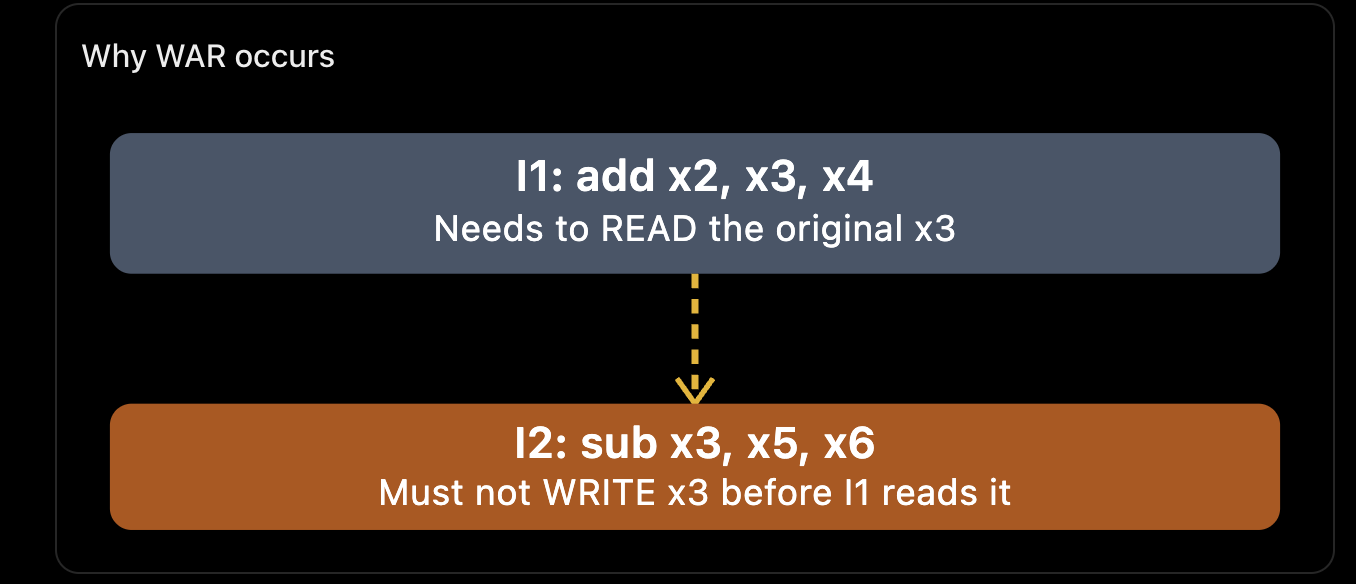

This is called:

$$
\boxed{\text{WAR}=\text{Write After Read}}
$$

### Exam Definition

> **WAR Dependency:** A WAR dependency occurs when a later instruction writes to a register that an earlier instruction must read, and executing the write too early could change the earlier instruction's input.

This is also called an **anti-dependency**.

---

## 3. The Most Important Comparison: RAW vs WAW vs WAR

Let's identify the register relationship.

### 3.1 RAW — True Dependency

```asm
I1: add x5, x1, x2    // Writes x5
I2: sub x6, x5, x3    // Reads x5
```

The second instruction requires data produced by the first.

### 3.2 WAW — Output Dependency

```asm
I1: add x5, x1, x2    // Writes x5
I2: sub x5, x3, x4    // Writes x5
```

Both instructions write the same destination.

### 3.3 WAR — Anti-Dependency

```asm
I1: add x6, x5, x2    // Reads x5
I2: sub x5, x3, x4    // Writes x5
```

The second instruction must not overwrite a value before the first has read it.

### 3.4 Quick Recognition Table

| Type | Earlier Instruction | Later Instruction |
|---|---|---|
| RAW | Writes X | Reads X |
| WAW | Writes X | Writes X |
| WAR | Reads X | Writes X |

> 💡 **Exam shortcut:** Always examine the instruction appearing second in the program. Does it Read or Write a register that the earlier instruction also accesses? The order of accesses gives you the dependency name.

---

## 4. Why Are WAW and WAR Called False Dependencies?

**Professor's Transcript:** Approximately 31:39–34:43

The professor explains that WAR and WAW arise because instructions reuse register names.

### 4.1 WAW Example

Consider WAW again:

```asm
I1: add x3, x5, x6
I2: add x3, x2, x1
```

Imagine assigning a different register to the first result when it doesn't need to be observed as `x3`:

```asm
I1: add x7, x5, x6
I2: add x3, x2, x1
```

Now the destination registers are different.

The WAW dependency disappears, provided the register renaming preserves any required uses of the original value.

Likewise, WAR hazards can be removed through appropriate register renaming.

This is the basis of **register renaming**, an important technique in out-of-order processors.

### 4.2 Why Can't RAW Be Removed by Register Renaming?

Consider:

```asm
I1: add x5, x1, x2
I2: sub x6, x5, x3
```

If I1 produces a value that I2 needs, renaming the register requires changing both references consistently.

The data dependency still exists.

$$
\boxed{\text{RAW = True data flow}}
$$

$$
\boxed{\text{WAW and WAR = Name dependencies}}
$$

---

## 5. Important Distinction for the Basic Five-Stage Pipeline

The professor specifically explains that WAW and WAR become problems when instructions can execute or complete out of order.

In the simple in-order, five-stage RISC-V pipeline we've been drawing:

- Instructions read registers in **ID**.
- Instructions write registers in **WB**.
- Register writes happen in program order.

Therefore, ordinary **WAW and WAR hazards do not arise** in that basic pipeline.

**RAW is the main data hazard we need to handle.**

A more advanced processor with out-of-order execution or variable-latency operations needs mechanisms to preserve these relationships.

---

## 6. What's Next in the Professor's Transcript?

At approximately **35:15**, the professor begins analyzing the performance penalty caused by RAW dependencies.

He compares:

1. Two consecutive dependent instructions.
2. Two dependent instructions separated by an independent instruction.

In his simplified pipeline model, the dependent instruction is stalled until the earlier instruction completes WB, with **no forwarding**.

That produces a different number of bubbles depending on how far apart the dependent instructions are.

We'll derive those penalties using pipeline diagrams rather than memorize them.

---



# Lecture 24 — RAW, Control and Structural Hazards

**Part 4 Transcript:** Approximately 35:15–47:00  
**Part 5 Transcript:** Approximately 47:00–59:31  
**Part 6 Transcript:** Approximately 59:31–1:02:12

---

## 1. RAW Hazards and Pipeline Penalties

### 1.1 Why Does RAW Produce Bubbles?

Consider the professor's example:

```asm
I1: add x2, x3, x4
I2: add x5, x2, x4
```

Instruction `I1` produces the value of `x2`.

Instruction `I2` needs `x2`.

In the professor's simplified five-stage pipeline:

- Registers are read in **ID**.
- ALU results are calculated in **EX**.
- Results are written into the register file in **WB**.

The model has **no forwarding**. Therefore, `I2` cannot safely read the new `x2` until `I1` completes WB.

Let's see exactly how that affects the pipeline.

---

## 2. Example 1 — RAW Between Consecutive Instructions

### 2.1 Schedule Without Hazards

Without hazards, the schedule would be:

| Instruction | C1 | C2 | C3 | C4 | C5 | C6 |
|---|---|---|---|---|---|---|
| I1 | IF | ID | EX | MEM | WB | — |
| I2 | — | IF | ID | EX | MEM | WB |

The problem occurs in **cycle 3**.

- `I1` is only in EX.
- `I2` wants to read `x2` in ID.
- The register file still contains the old `x2`.

So `I2` must wait.

### 2.2 Correct Schedule According to the Professor's Model

**RAW hazard — 3-cycle stall**

| Inst. | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
|---|---|---|---|---|---|---|---|---|---|
| I1 | IF | ID | EX | MEM | WB | — | — | — | — |
| I2 | — | IF | St | St | St | ID | EX | MEM | WB |

`St` = I2 is held in Fetch; three empty slots appear in Decode.

The final instruction completes in **cycle 9**.

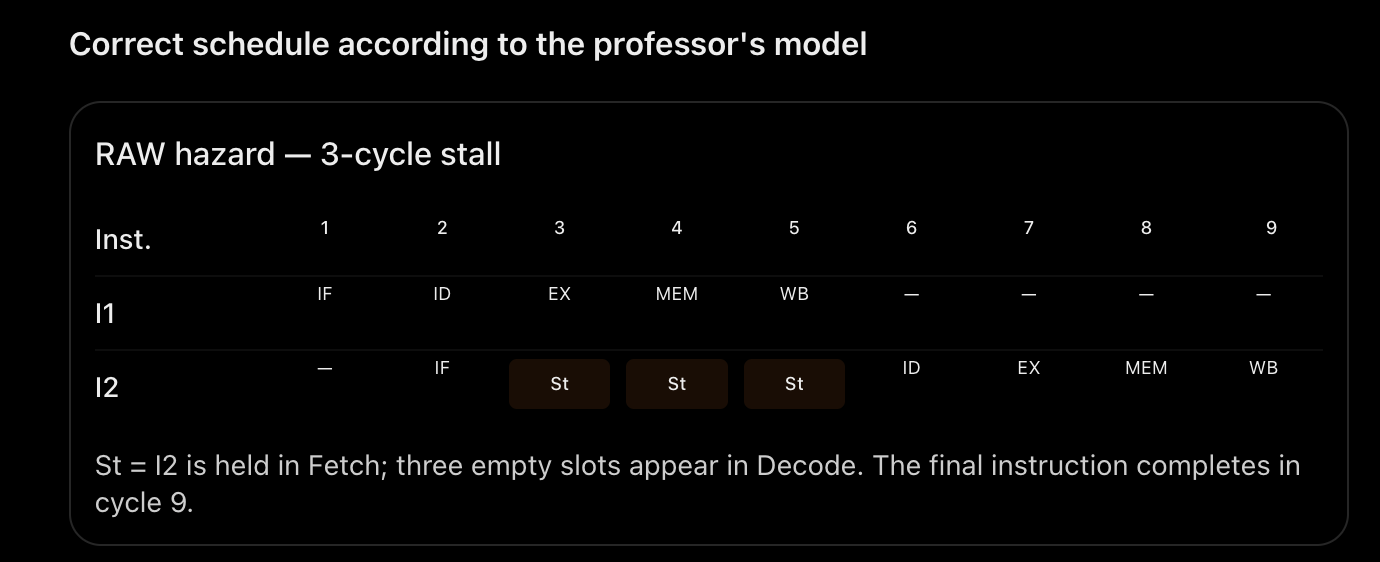

### 2.3 Cycle-by-Cycle Reasoning

- **Cycle 3:** I1 executes, but hasn't written `x2`. I2 waits.
- **Cycle 4:** I1 enters MEM. I2 still waits.
- **Cycle 5:** I1 enters WB and writes `x2` by the end of the cycle.
- **Cycle 6:** I2 can finally read the correct `x2` in ID.

So the additional delay is:

$$
\boxed{\text{RAW penalty}=3\text{ cycles}}
$$

> 📌 This is the penalty for the professor's specific no-forwarding, end-of-WB-write timing model, not a universal RAW penalty.

---

## 3. Calculate CPI With and Without the Hazard

First, define the quantities:

$$
CPI=\frac{\text{Total Clock Cycles}}{\text{Number of Instructions}}
$$

### 3.1 Without Dependency

Two instructions complete in 6 cycles:

$$
CPI_{\text{ideal}}=\frac{6}{2}=\boxed{3}
$$

### 3.2 With RAW Dependency

Two instructions complete in 9 cycles:

$$
CPI_{\text{actual}}=\frac{9}{2}=\boxed{4.5}
$$

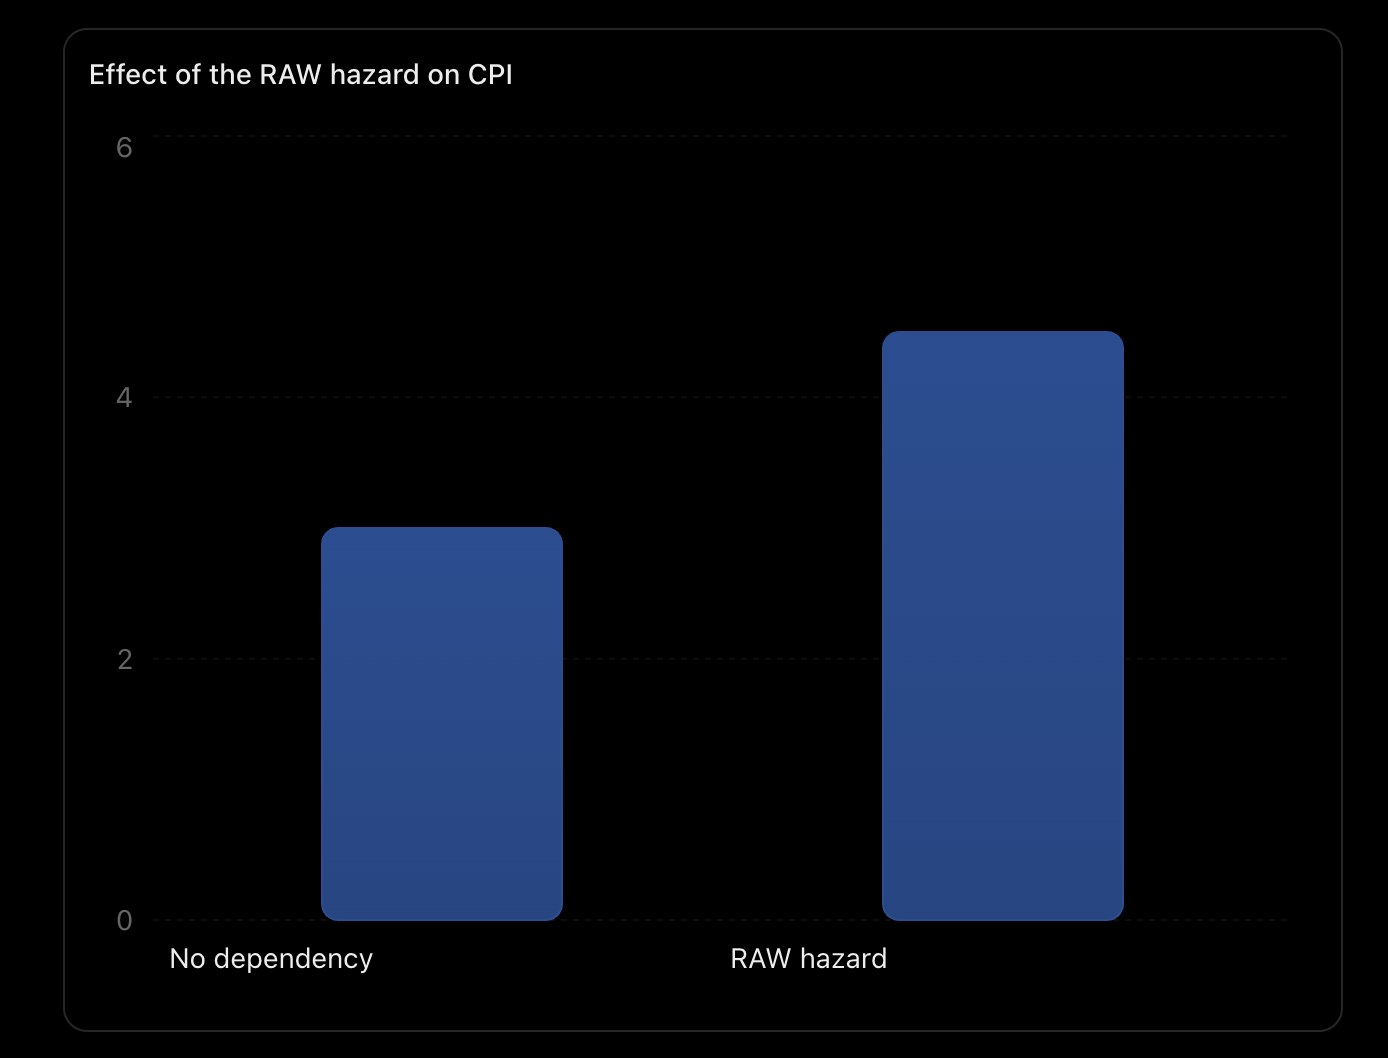

### 3.3 Comparison

| Situation | Total Cycles | CPI |
|---|---|---|
| No dependency | 6 | 3 |
| RAW hazard | 9 | **4.5** |

The professor's conclusion:

$$
\boxed{
\text{More bubbles}
\Rightarrow
\text{Higher CPI}
\Rightarrow
\text{Lower IPC}
}
$$

> 📌 **Important distinction:** The ideal CPI of this two-instruction example is 3 because pipeline filling and draining dominate. The ideal steady-state CPI for a long instruction sequence approaches 1.

---

## 4. Example 2 — What If There's an Independent Instruction Between Them?

**Professor's Transcript:** Approximately 42:10–47:00

Consider three instructions:

```asm
I1: add x2, x3, x4
I2: sub x5, x6, x7
I3: add x9, x2, x8
```

### 4.1 Check the Dependencies

- **I1 → I2:** No dependency.
- **I2 → I3:** No dependency.
- **I1 → I3:** RAW dependency on `x2`.

Because `I2` is independent, it can execute while `I1` is progressing toward WB.

Let's dry-run the processor.

### 4.2 RAW With One Independent Instruction in Between

| Inst. | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
|---|---|---|---|---|---|---|---|---|---|---|
| I1 | IF | ID | EX | MEM | WB | — | — | — | — |
| I2 | — | IF | ID | EX | MEM | WB | — | — | — |
| I3 | — | — | IF | St | St | ID | EX | MEM | WB |

`I3` waits for `I1` to complete WB, but only **two extra cycles** are required.
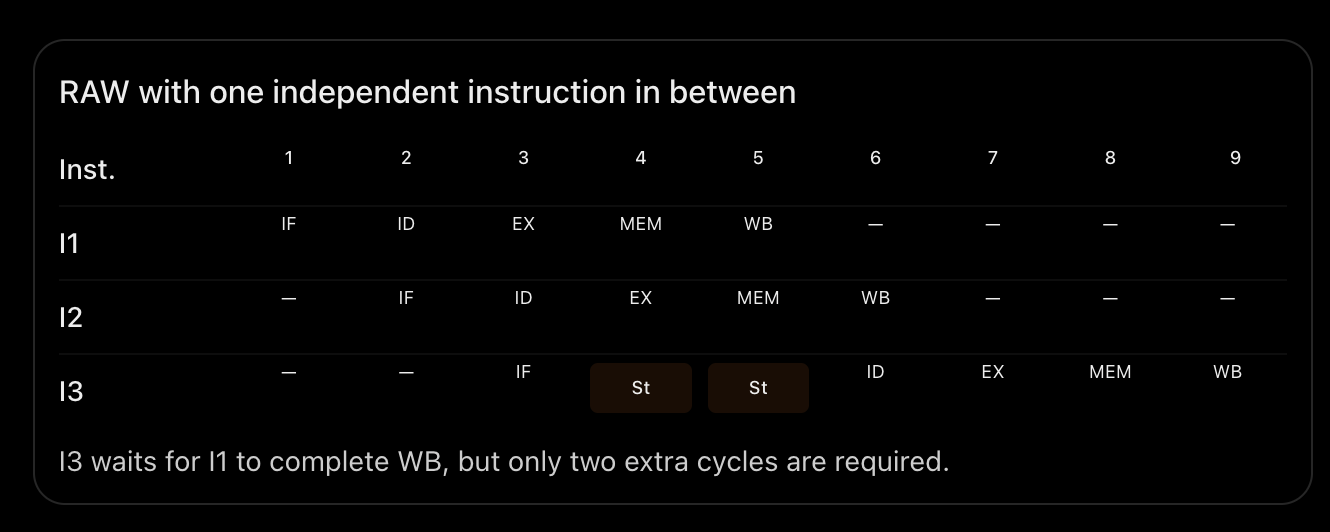

### 4.3 Why Are There Only Two Stalls?

- **Cycle 3:** I3 is fetched.
- **Cycle 4:** I3 wants ID, but I1 has not written `x2`, so I3 waits.
- **Cycle 5:** I1 performs WB; I3 still waits.
- **Cycle 6:** I3 reads the updated `x2`.

Therefore:

$$
\boxed{\text{Penalty}=2\text{ cycles}}
$$

### 4.4 Calculate Total Cycles and CPI

Without the dependency, three instructions would require:

$$
3+5-1=7\text{ cycles}
$$

With two stalls:

$$
7+2=\boxed{9\text{ cycles}}
$$

Therefore:

$$
CPI=\frac{9}{3}=\boxed{3}
$$

### 4.5 What Did We Discover?

Compare the professor's examples:

| Instructions Between Producer and Consumer | RAW Stall Penalty |
|---|---|
| 0 — Consecutive instructions | 3 cycles |
| 1 independent instruction | 2 cycles |
| 2 independent instructions | 1 cycle |
| 3 or more independent instructions | **0 cycles** |

This table follows the professor's specific timing assumption that the consumer reads only after the producer's WB cycle is completed.

**Why does the penalty decrease?**

Because independent instructions provide time for the producer to finish writing its result.

This observation is also the foundation of **instruction scheduling**, which we'll encounter when discussing hazard solutions.

---
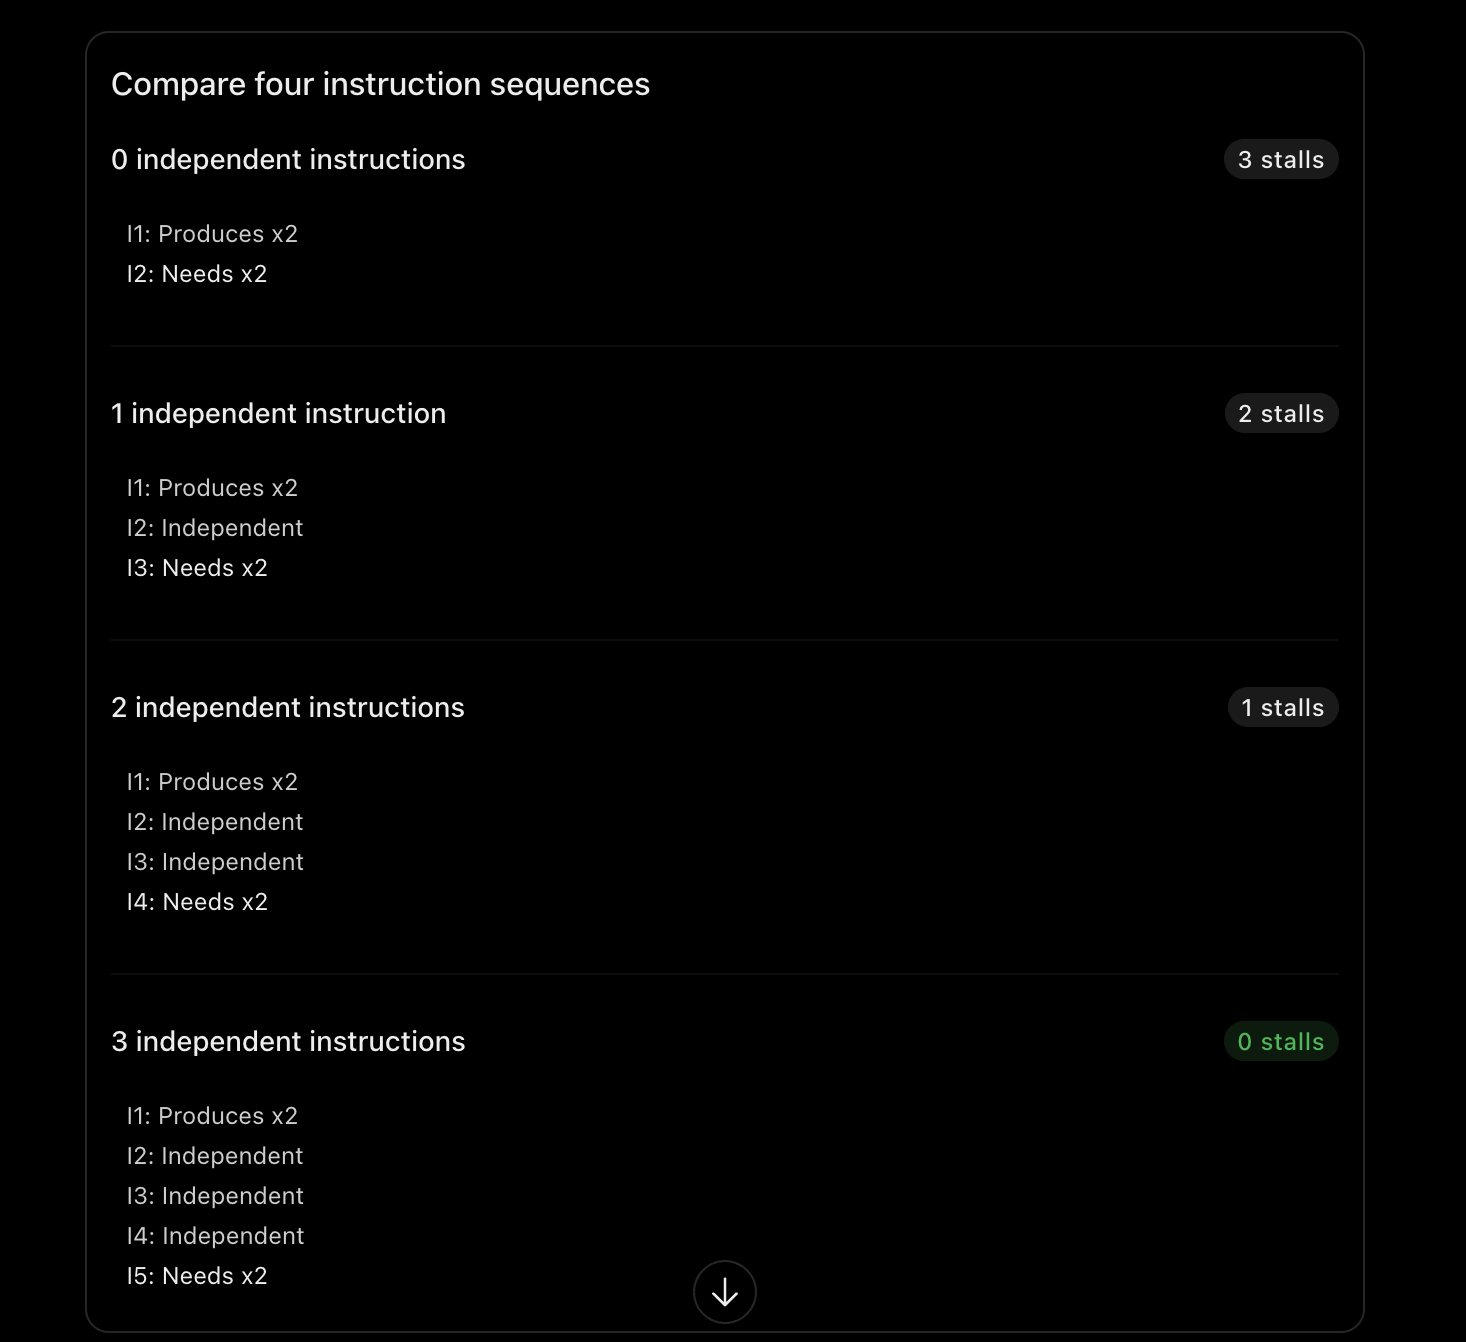

## 5. Lecture 24 — Part 5: Control Hazards

**Professor's Transcript:** Approximately 47:00–59:31

### 5.1 Why Do Branches Create Hazards?

Consider:

```asm
I1: add x2, x3, x4
I2: beq x5, x6, TARGET
I3: add x7, x8, x9
I4: sub x10, x11, x12

TARGET:
I12: add x13, x14, x15
```

If `x5 == x6`, the branch is **taken**, and execution should proceed to `I12`.

If `x5 != x6`, the branch is **not taken**, and execution should proceed to `I3`.

But here is the problem.

**When does the processor know whether the branch is taken?**

In our five-stage pipeline, the branch condition is resolved in the **EX stage**.

Until then, the processor cannot be certain which instruction should execute next.

---

## 6. What Happens If We Keep Fetching Sequential Instructions?

### 6.1 Branch Instruction I2 — Resolved in EX

| Cycle | I2 (Branch) | Sequential Instructions |
|---|---|---|
| 2 | IF | — |
| 3 | ID | I3 enters IF |
| 4 | EX | I3 in ID; I4 in IF |

At the end of cycle 4, the branch outcome becomes known.

If the branch is taken, `I3` and `I4` belong to the wrong execution path.

They must not be allowed to update the architectural state.

The processor must either:

- Avoid fetching them, or
- Invalidate them before they cause incorrect results.

This is a **control hazard**.

---

## 7. Professor's Solution — Stall Until the Branch Is Resolved

The professor introduces the simplest approach:

1. Fetch the branch.
2. Stop fetching new instructions.
3. Wait until the branch reaches EX.
4. Determine whether it is taken.
5. Resume fetching from the correct address.

In this simplified model, the processor loses **two instruction-fetch opportunities**.

$$
\boxed{\text{Control hazard penalty}=2\text{ cycles}}
$$

### 7.1 Why Two Cycles?

Because the branch enters ID in cycle 3 and EX in cycle 4.

Its outcome is available only after EX, so useful fetching can resume in cycle 5.

### 7.2 Branch Stall Illustration

| Stage | 2 | 3 | 4 | 5 | 6 | 7 |
|---|---|---|---|---|---|---|
| IF | I2 | — | — | I12 | I13 | I14 |
| ID | — | I2 | — | — | I12 | I13 |
| EX | — | — | I2 | — | — | I12 |

`I2` is a taken branch to `I12`.

Fetch remains idle in **cycles 3 and 4**.

This diagram shows the simplified branch-stall approach, not a branch predictor.

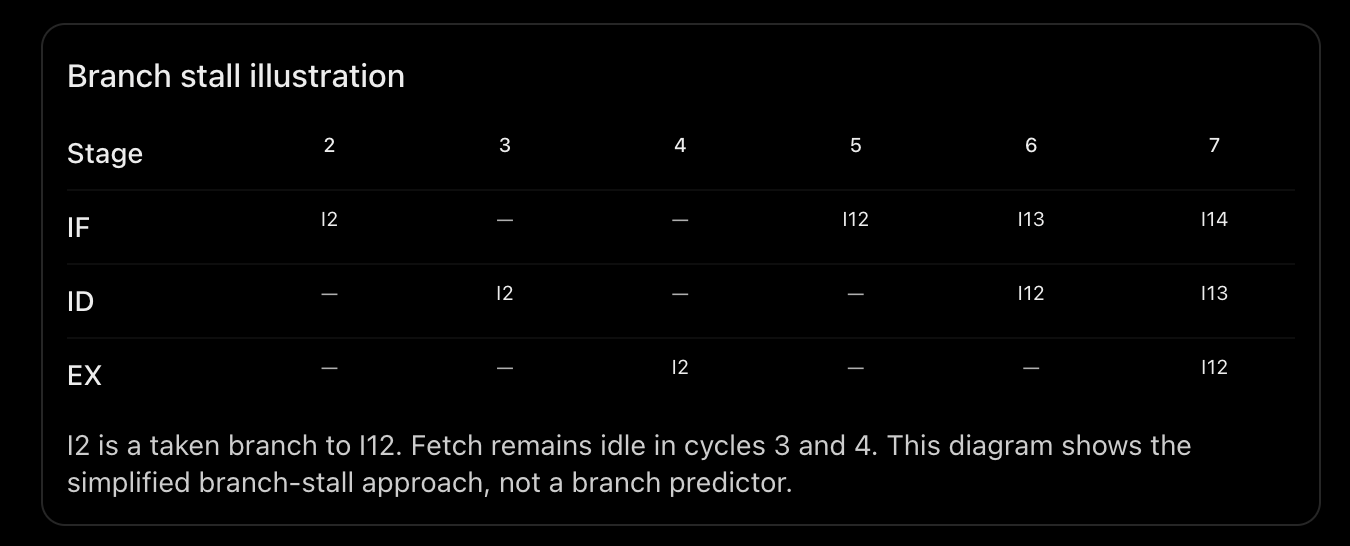

### 7.3 What About Branch Prediction?

Instead of waiting, a processor may predict whether a branch is taken and continue fetching instructions.

- If the prediction is **correct**, much of the stall overhead can be avoided.
- If the prediction is **wrong**, the wrong-path instructions must be flushed.

The professor reserves branch prediction and other control-hazard solutions for later lectures.

---

## 8. Lecture 24 — Part 6: Structural Hazards

**Professor's Transcript:** Approximately 59:31–1:02:12

### 8.1 Definition

> **Structural Hazard:** A structural hazard occurs when two instructions need a hardware resource at the same time, but that resource cannot serve both simultaneously.

### 8.2 Example — Shared Memory

Suppose the processor has only **one memory port**, shared by instruction fetching and data access.

In the same clock cycle:

- `I1` is a `lw` instruction in MEM, trying to read data.
- `I4` is in IF, trying to fetch an instruction.

Both require the memory port.

Since only one access can happen at a time, the other instruction must wait.

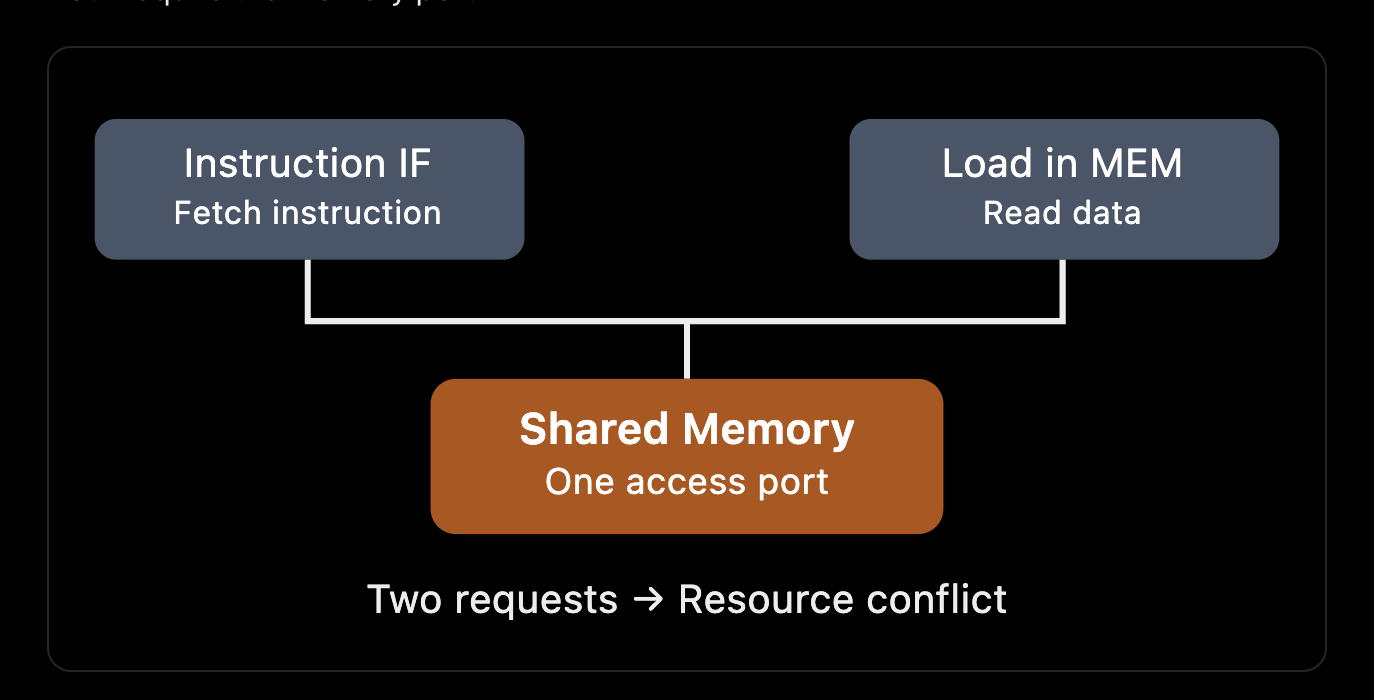

### 8.3 Solutions

- Provide separate instruction and data memories or caches.
- Use a suitably multiported memory.
- Add or duplicate hardware resources where feasible.
- Stall one of the competing operations.

The professor briefly introduces structural hazards and concentrates mainly on data and control hazards.

---

## 9. Lecture 24 — Exam-Ready Summary

| Hazard | Cause | Typical Solution |
|---|---|---|
| RAW | Later instruction needs a value produced earlier | Forwarding or stalling |
| WAW | Two instructions write the same destination | Preserve write order, register renaming |
| WAR | Later instruction overwrites a value needed earlier | Preserve read-before-write order, register renaming |
| Control | Next instruction address is unresolved | Stalling, prediction, flushing |
| Structural | Hardware resource conflict | More resources or stalling |

### 9.1 Professor's Simplified Penalty Results

| Situation | Penalty |
|---|---|
| Consecutive RAW, no forwarding | 3 cycles |
| RAW with one independent instruction between | 2 cycles |
| Branch resolved in EX using fetch stalling | 2 cycles |

> 📌 These values depend on the exact pipeline design and timing conventions, so always check the assumptions in a numerical question.

### 9.2 Formula Connecting Hazards to Performance

$$
\boxed{\text{Total Cycles}=n+k-1+\text{Stall Cycles}}
$$

And:

$$
\boxed{CPI=\frac{\text{Total Cycles}}{n}}
$$

Where:

- $n$ = Number of instructions.
- $k$ = Number of pipeline stages.

---
